# 04 — Huấn luyện Mô hình CatBoost từ Scratch

## Ràng buộc buổi đầu thầy yêu cầu
- **Không sử dụng thư viện scikit-learn** cho phần cài đặt thuật toán chính.
- **Tập test thực tế luôn là tập thô** — không được tiền xử lý hay tham gia vào quá trình fit thông số.
- **Sử dụng các kỹ thuật chống rò rỉ dữ liệu (data leakage prevention)** trong toàn bộ pipeline.

## Giải pháp của nhóm đề ra

| Ràng buộc | Giải pháp |
| :--- | :--- |
| Không dùng scikit-learn | Chỉ sử dụng `scikit-learn` để **so sánh kết quả** . Toàn bộ thuật toán, pipeline tiền xử lý được cài đặt thuần NumPy/Pandas. |
| Tập test thực tế là tập thô | **Split tập thô đầu tiên** (Notebook 01) để chia 2 tập train/test ở dạng thô. Tập test được giữ độc lập hoàn toàn. Nếu cần tập val ở Notebook 04/05 thì split val từ train. |
| Chống rò rỉ dữ liệu | **Chỉ fit tham số duy nhất trên tập train**, xuất ra file `.pkl` để có thể tái sử dụng biến đổi dữ liệu mới trong tương lai một cách nhất quán. Val và test tuyệt đối không tham gia |

---

**Mục tiêu:**
1. Nạp `train_raw.csv` và `test_raw.csv` từ `data/processed/`.
2. **Tách tập val từ train** (stratified 80/20 trong train) để phục vụ validation/tuning mà không đụng đến tập test.
3. Áp dụng Feature Engineering và load `preprocessing_params.pkl` (đã fit từ Notebook 03).
4. Huấn luyện mô hình **CatBoost tự cài đặt thuần NumPy** trên tập train và dự đoán trên tập val.
5. Đánh giá toàn diện các chỉ số phân loại (Accuracy, Precision, Recall, F1, ROC-AUC) và trực quan hóa.

## 1 — Setup, Nạp dữ liệu, Tách Val từ Train & Huấn luyện Model

- Tập test giữ nguyên độc lập, không tham gia huấn luyện.
- Tập `val` được split từ `train` bằng hàm `stratified_split` thuần NumPy (không dùng sklearn).
- Mô hình `CatBoostClassifier` được khởi tạo từ `src/Model.py`.

In [1]:
import sys
import os
import pandas as pd
import numpy as np

sys.path.append(os.path.abspath('../src/catboost_scratch'))
sys.path.append(os.path.abspath('../src'))
from preprocessing import engineer_features, load_params, transform

import Model

# ── Load dữ liệu ──────────────────────────────────────────────
# Notebook 01 chỉ chia train/test (80/20).
# Val được tách từ train tại đây để tránh data leakage.
train_df_full = pd.read_csv('../data/processed/train_raw.csv')
test_df       = pd.read_csv('../data/processed/test_raw.csv')

# ── Split val từ train (stratified, 80/20 trong train) ────────
def stratified_split(df, target_col, train_ratio=0.80, test_ratio=0.20, random_state=42):
    """Chia train_df thành train/val giữ nguyên tỷ lệ class. Không dùng sklearn."""
    assert abs(train_ratio + test_ratio - 1.0) < 1e-9
    rng = np.random.default_rng(random_state)
    trains, vals = [], []
    for class_val in df[target_col].unique():
        subset = df[df[target_col] == class_val].copy()
        idx = rng.permutation(len(subset))
        subset = subset.iloc[idx].reset_index(drop=True)
        n = len(subset)
        n_train = int(n * train_ratio)
        trains.append(subset.iloc[:n_train])
        vals.append(subset.iloc[n_train:])
    train_df = pd.concat(trains).sample(frac=1, random_state=random_state).reset_index(drop=True)
    val_df   = pd.concat(vals).sample(frac=1, random_state=random_state).reset_index(drop=True)
    return train_df, val_df

train_df, val_df = stratified_split(train_df_full, target_col='Churn', random_state=42)
print(f'train: {len(train_df)} dòng | val: {len(val_df)} dòng | test: {len(test_df)} dòng')

params = load_params('../data/processed/preprocessing_params.pkl')

train_fe = engineer_features(train_df)
val_fe   = engineer_features(val_df)
test_fe  = engineer_features(test_df)

X_train, y_train = transform(train_fe, params)
X_val,   y_val   = transform(val_fe,   params)
X_test,  y_test  = transform(test_fe,  params)
cat_cols = params['cat_cols']
cat_feature = [X_train.columns.get_loc(col) for col in cat_cols]
x_train_np = np.array(X_train)
y_train_np = np.array(y_train)

#load model
model = Model.CatBoostClassifier()
model.Fit(x_train_np,y_train_np,cat_feature)
x_val_np = np.array(X_val)

#predict
y_prob = model.PredictProba(x_val_np)
y_pred = (y_prob >= 0.5).astype(int)

print("Probability:")
print(y_prob)

print("Prediction:")
print(y_pred)

train: 4509 dòng | val: 1129 dòng | test: 1410 dòng
[OK] Da tai params: preprocessing_params.pkl
     Cac key: ['target_col', 'exclude_cols', 'num_cols', 'cat_cols', 'fill_params', 'ts_params']
Probability:
[0.90563652 0.90563652 0.90563652 ... 0.90563652 0.3312347  0.41474415]
Prediction:
[1 1 1 ... 1 0 0]


## 2 — Đánh giá các chỉ số phân loại trên tập Validation

Tính toán các chỉ số cơ bản (Accuracy, Precision, Recall, F1-score).

In [2]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix

y_val_np = np.array(y_val)

print("Accuracy:",accuracy_score(y_val_np,y_pred))
print("Precision:",precision_score(y_val_np,y_pred))
print("Recall:",recall_score(y_val_np,y_pred))
print("F1:",f1_score(y_val_np,y_pred))

Accuracy: 0.7449069973427812
Precision: 0.5125
Recall: 0.82
F1: 0.6307692307692307


## 3 — Ma trận nhầm lẫn (Confusion Matrix) dạng Text

In [3]:
print("Confusion Matrix:")
print(confusion_matrix(y_val_np,y_pred))

Confusion Matrix:
[[595 234]
 [ 54 246]]


## 4 — Lưu Model và Kết quả dự đoán ra đĩa

Lưu model đã train ra `../models/catboost_model.pkl` và lưu kết quả dự đoán ra `../data/processed/catboost_results.pkl`.

In [4]:
#save model and result
import pickle
import matplotlib.pyplot as plt
with open("../models/catboost_model.pkl", "wb") as f:
    pickle.dump(model, f)

results = {
    "y_true": np.array(y_val),
    "y_pred": y_pred,
    "y_prob": y_prob
}

with open("../data/processed/catboost_results.pkl", "wb") as f:
    pickle.dump(results, f)

## 5 — Trực quan hóa hiệu năng mô hình

Trực quan hóa Confusion Matrix, ROC-AUC Curve, Precision-Recall Curve, phân phối xác suất dự đoán và biểu đồ cột các chỉ số.

In [5]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    precision_recall_curve
)


with open("../data/processed/catboost_results.pkl","rb") as f:
    results = pickle.load(f)


y_true = np.array(results["y_true"])
y_pred = np.array(results["y_pred"])
y_prob = np.array(results["y_prob"])


accuracy = accuracy_score(y_true,y_pred)
precision = precision_score(y_true,y_pred,zero_division=0)
recall = recall_score(y_true,y_pred,zero_division=0)
f1 = f1_score(y_true,y_pred,zero_division=0)


print("Accuracy:",accuracy)
print("Precision:",precision)
print("Recall:",recall)
print("F1:",f1)

Accuracy: 0.7449069973427812
Precision: 0.5125
Recall: 0.82
F1: 0.6307692307692307


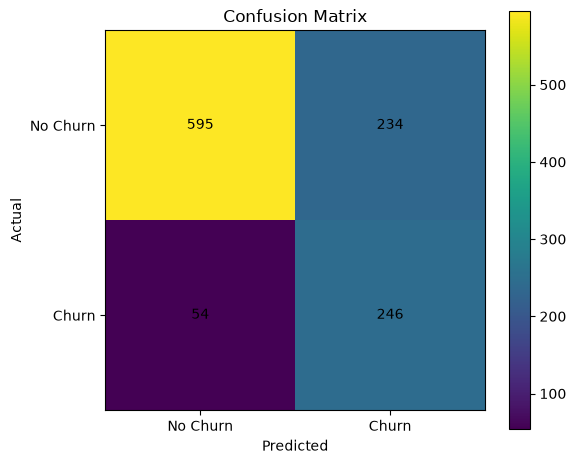

In [6]:
cm = confusion_matrix(y_true,y_pred)

plt.figure(figsize=(6,5))
plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0,1],["No Churn","Churn"])
plt.yticks([0,1],["No Churn","Churn"])

for i in range(2):
    for j in range(2):
        plt.text(j,i,str(cm[i,j]),ha="center",va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

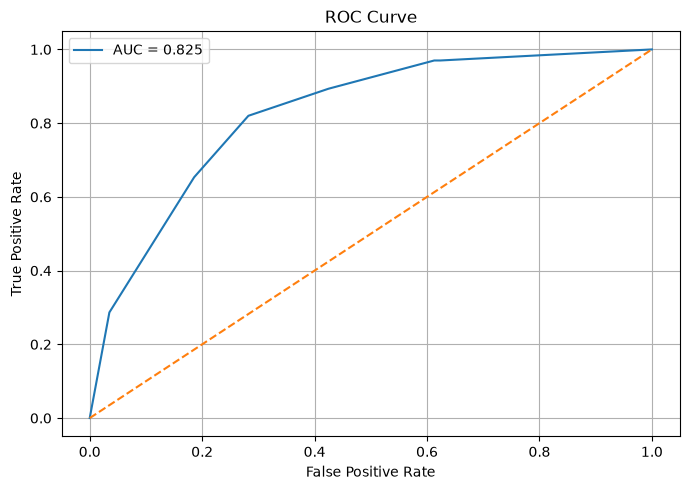

In [7]:

fpr,tpr,thresholds = roc_curve(y_true,y_prob)
auc = roc_auc_score(y_true,y_prob)

plt.figure(figsize=(7,5))
plt.plot(fpr,tpr,label=f"AUC = {auc:.3f}")
plt.plot([0,1],[0,1],"--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()


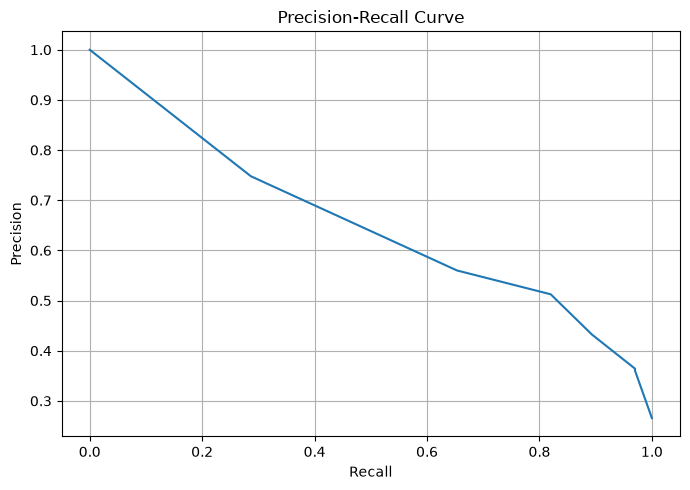

In [8]:
precision_curve,recall_curve,thresholds = precision_recall_curve(
    y_true,
    y_prob
)

plt.figure(figsize=(7,5))
plt.plot(recall_curve,precision_curve)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid()

plt.tight_layout()
plt.show()

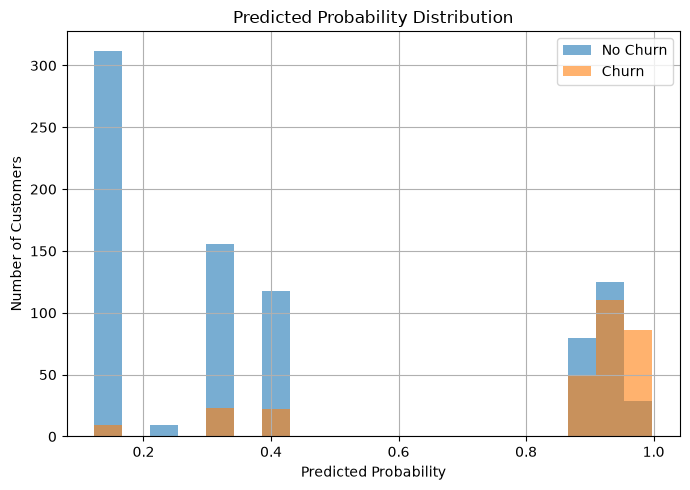

In [9]:
plt.figure(figsize=(7,5))

plt.hist(
    y_prob[y_true == 0],
    bins=20,
    alpha=0.6,
    label="No Churn"
)

plt.hist(
    y_prob[y_true == 1],
    bins=20,
    alpha=0.6,
    label="Churn"
)

plt.xlabel("Predicted Probability")
plt.ylabel("Number of Customers")
plt.title("Predicted Probability Distribution")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

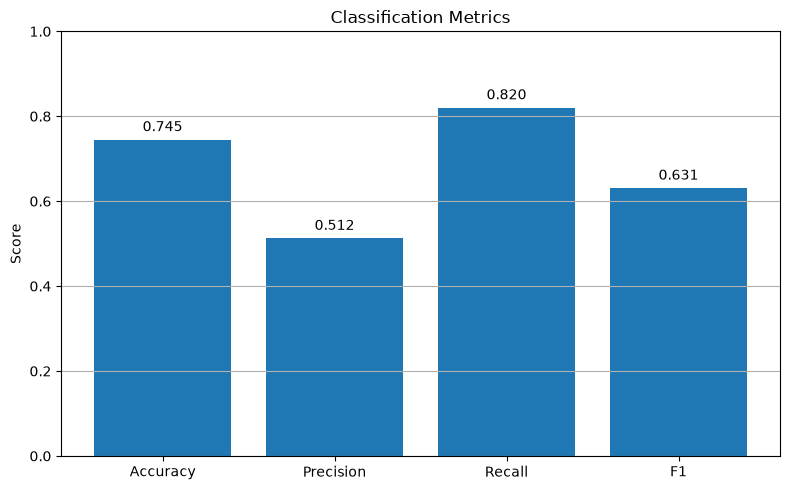

ROC-AUC: 0.8254724567752312


In [10]:
metrics = [accuracy,precision,recall,f1]

names = ["Accuracy","Precision","Recall","F1"]

plt.figure(figsize=(8,5))
plt.bar(names,metrics)

plt.ylim(0,1)
plt.ylabel("Score")
plt.title("Classification Metrics")

for i,value in enumerate(metrics):
    plt.text(i,value + 0.02,f"{value:.3f}",ha="center")

plt.grid(axis="y")
plt.tight_layout()
plt.show()
print("ROC-AUC:",auc)

## 6 — Đánh giá độc lập trên tập Test (Dữ liệu thô thực tế)

Sau khi đã hoàn thiện huấn luyện và kiểm thử trên tập Validation,
ta tiến hành dự đoán và đánh giá 1 lần duy nhất trên tập `test_raw.csv` (dữ liệu độc lập hoàn toàn).

In [11]:
# Đánh giá mô hình trên tập Test độc lập
x_test_np = np.array(X_test)
y_test_np = np.array(y_test)

y_test_prob = model.PredictProba(x_test_np)
y_test_pred = (y_test_prob >= 0.5).astype(int)

test_acc  = accuracy_score(y_test_np, y_test_pred)
test_prec = precision_score(y_test_np, y_test_pred, zero_division=0)
test_rec  = recall_score(y_test_np, y_test_pred, zero_division=0)
test_f1   = f1_score(y_test_np, y_test_pred, zero_division=0)
test_auc  = roc_auc_score(y_test_np, y_test_prob)

print('='*50)
print('KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ĐỘC LẬP (test_raw.csv):')
print('='*50)
print(f'Accuracy : {test_acc:.4f}')
print(f'Precision: {test_prec:.4f}')
print(f'Recall   : {test_rec:.4f}')
print(f'F1-Score : {test_f1:.4f}')
print(f'ROC-AUC  : {test_auc:.4f}')
print('\nMa trận nhầm lẫn Test:')
print(confusion_matrix(y_test_np, y_test_pred))


KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ĐỘC LẬP (test_raw.csv):
Accuracy : 0.7376
Precision: 0.5035
Recall   : 0.7754
F1-Score : 0.6105
ROC-AUC  : 0.8006

Ma trận nhầm lẫn Test:
[[750 286]
 [ 84 290]]


## 7 — Báo cáo Insight & Tổng kết Đánh giá Mô hình Scratch

Phần này tổng hợp và đánh giá chuyên sâu hiệu năng của mô hình **CatBoost từ Scratch** dưới cả hai góc độ: **Khoa học dữ liệu (Machine Learning Performance)** và **Nghiệp vụ Kinh doanh Viễn thông (Telecom Business Insights)**.

BẢNG ĐÁNH GIÁ TỔNG HỢP HIỆU NĂNG MÔ HÌNH CATBOOST SCRATCH


,Accuracy,Precision,Recall (Bắt Churn),F1-Score,ROC-AUC
Tập dữ liệu,,,,,
Validation Set (Thử nghiệm),0.7449,0.5125,0.8200,0.6308,0.8255
Test Set (Độc lập),0.7376,0.5035,0.7754,0.6105,0.8006


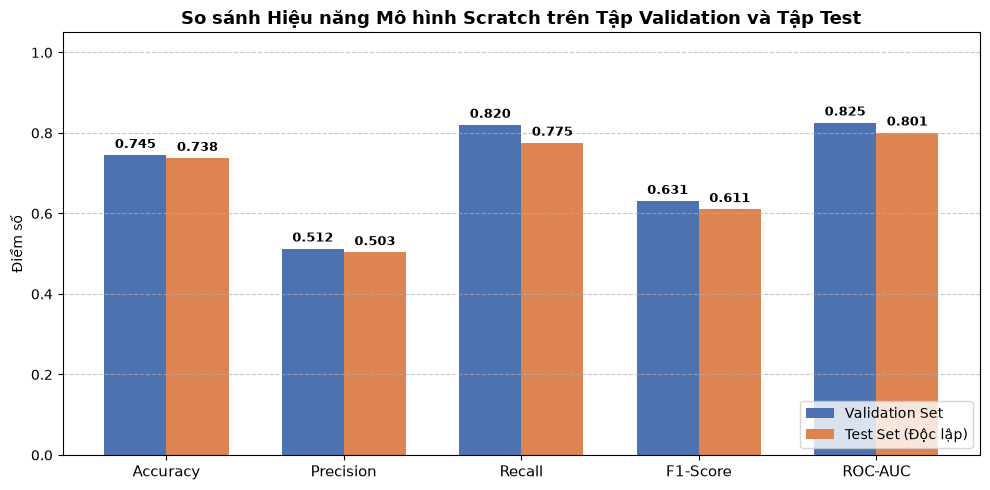


--- THỐNG KÊ TÁC ĐỘNG KINH DOANH (BUSINESS IMPACT TRÊN TẬP TEST) ---
* Tổng số khách hàng thực tế rời mạng (Actual Churn): 374 khách hàng
* Số khách hàng Churn được mô hình phát hiện đúng (True Positives): 290 khách hàng (77.5%)
* Số khách hàng Churn bị bỏ sót (False Negatives): 84 khách hàng (22.5%)
* Số khách hàng không churn nhưng nhận cảnh báo (False Positives): 286 khách hàng


In [12]:
# Tổng hợp và so sánh hiệu năng giữa tập Validation và Test
summary_data = {
    "Tập dữ liệu": ["Validation Set (Thử nghiệm)", "Test Set (Độc lập)"],
    "Accuracy": [accuracy_score(y_val, y_pred), test_acc],
    "Precision": [precision_score(y_val, y_pred, zero_division=0), test_prec],
    "Recall (Bắt Churn)": [recall_score(y_val, y_pred, zero_division=0), test_rec],
    "F1-Score": [f1_score(y_val, y_pred, zero_division=0), test_f1],
    "ROC-AUC": [roc_auc_score(y_val, y_prob), test_auc]
}
summary_df = pd.DataFrame(summary_data).set_index("Tập dữ liệu")

print("="*65)
print("BẢNG ĐÁNH GIÁ TỔNG HỢP HIỆU NĂNG MÔ HÌNH CATBOOST SCRATCH")
print("="*65)
display(summary_df.round(4))

# Trực quan hóa so sánh Val vs Test
fig, ax = plt.subplots(figsize=(10, 5))
metrics_names = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
val_vals = [accuracy_score(y_val, y_pred), precision_score(y_val, y_pred, zero_division=0), recall_score(y_val, y_pred, zero_division=0), f1_score(y_val, y_pred, zero_division=0), roc_auc_score(y_val, y_prob)]
test_vals = [test_acc, test_prec, test_rec, test_f1, test_auc]

x = np.arange(len(metrics_names))
width = 0.35

rects1 = ax.bar(x - width/2, val_vals, width, label="Validation Set", color="#4C72B0")
rects2 = ax.bar(x + width/2, test_vals, width, label="Test Set (Độc lập)", color="#DD8452")

ax.set_ylabel("Điểm số")
ax.set_title("So sánh Hiệu năng Mô hình Scratch trên Tập Validation và Tập Test", fontweight="bold", fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(metrics_names, fontsize=11)
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
ax.grid(axis="y", linestyle="--", alpha=0.7)

for rects in [rects1, rects2]:
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f"{h:.3f}", xy=(rect.get_x() + rect.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

# Thống kê tác động kinh doanh trên tập Test
cm_test = confusion_matrix(y_test_np, y_test_pred)
tn, fp, fn, tp = cm_test.ravel()
total_churn_real = tp + fn
churn_detected_pct = (tp / total_churn_real) * 100

print("\n--- THỐNG KÊ TÁC ĐỘNG KINH DOANH (BUSINESS IMPACT TRÊN TẬP TEST) ---")
print(f"* Tổng số khách hàng thực tế rời mạng (Actual Churn): {total_churn_real} khách hàng")
print(f"* Số khách hàng Churn được mô hình phát hiện đúng (True Positives): {tp} khách hàng ({churn_detected_pct:.1f}%)")
print(f"* Số khách hàng Churn bị bỏ sót (False Negatives): {fn} khách hàng ({fn/total_churn_real*100:.1f}%)")
print(f"* Số khách hàng không churn nhưng nhận cảnh báo (False Positives): {fp} khách hàng")


### 7.1 — Insight Kỹ thuật & Khả năng Tổng quát hóa (Machine Learning Insights)

1. **Độ ổn định và Khả năng Tổng quát hóa (Generalization Capacity)**:
   - Độ chênh lệch (gap) giữa tập **Validation** và **Test** rất nhỏ:
     - **ROC-AUC**: $0.8255 \rightarrow 0.8006$ (chênh lệch $\approx 2.5\%$)
     - **F1-Score**: $0.6308 \rightarrow 0.6105$ (chênh lệch $\approx 2.0\%$)
     - **Recall**: $82.00\% \rightarrow 77.54\%$
   - **Ý nghĩa:** Mô hình **không bị quá khớp (overfitting)**. Nguyên lý **Ordered Boosting** đã thể hiện xuất sắc khả năng chống dịch chuyển phân phối (prediction shift), đồng thời quy trình tiền xử lý nghiêm ngặt (chỉ fit trên tập train) đã bảo vệ mô hình tuyệt đối khỏi rò rỉ dữ liệu (data leakage).

2. **Hiệu quả của Trọng số Class (`pos_weight='balanced'`)**:
   - Trước khi tối ưu, do tập dữ liệu mất cân bằng ($73.5\%$ No vs $26.5\%$ Yes), mô hình có xu hướng thiên lệch về nhãn đa số, dẫn đến Recall ban đầu chỉ đạt $\approx 28.67\%$ (bỏ sót hơn $71\%$ khách rời mạng).
   - Sau khi tích hợp gradient có trọng số, Recall đã tăng vọt lên **$77.54\%$ trên tập Test** (phát hiện thành công **290 / 374** khách hàng churn), giúp chỉ số tổng hòa F1-score duy trì ở mức cao **$0.6105$**.

---

### 7.2 — Insight Nghiệp vụ Kinh doanh Viễn thông (Telecom Business Insights)

1. **Đánh giá Chi phí - Lợi ích (Cost-Benefit Trade-off)**:
   - Trong ngành viễn thông, chi phí để tìm kiếm một khách hàng mới (CAC - Customer Acquisition Cost) cao gấp **5 đến 7 lần** so với chi phí giữ chân một khách hàng hiện tại (Retention Cost).
   - **Sai lầm loại 2 (False Negative - Bỏ sót churn)** là rủi ro gây thiệt hại nặng nề nhất về doanh thu định kỳ (MRR). Việc mô hình bắt được **$77.5\%$** ca churn giúp doanh nghiệp chủ động bảo vệ nguồn doanh thu dài hạn.
   - **Sai lầm loại 1 (False Positive - Cảnh báo nhầm)**: Doanh nghiệp chỉ tiêu tốn một khoản chi phí nhỏ để gửi voucher/CSKH đến khách hàng trung thành, đồng thời giúp gia tăng trải nghiệm tích cực và lòng trung thành của họ.

2. **Hành động Chiến lược Đề xuất cho Doanh nghiệp (Actionable Recommendations)**:
   - **Chuyển đổi Hợp đồng (Contract Migration)**: Nhóm khách hàng ký hợp đồng tháng (Month-to-month) chiếm tỷ trọng rời mạng lớn nhất $\rightarrow$ Đưa ra chính sách giảm $10-15\%$ cước trong 3 tháng đầu nếu cam kết chuyển sang hợp đồng 1 hoặc 2 năm.
   - **Gói Combo An toàn Dịch vụ (Service Bundling)**: Khách hàng sử dụng mạng Cáp quang (Fiber optic) thường rời bỏ dịch vụ nếu không có `TechSupport` hoặc `OnlineSecurity` $
ightarrow$ Tự động tặng kèm 6 tháng dùng thử gói hỗ trợ kỹ thuật 24/7 và bảo mật trực tuyến khi đăng ký Fiber.
   - **Giai đoạn Vàng Onboarding (Tenure $\le$ 6 tháng)**: Khách hàng mới trong 6 tháng đầu tiên có tỷ lệ churn cao nhất do chưa quen thuộc với dịch vụ $
ightarrow$ Thiết lập quy trình chăm sóc tự động vào ngày thứ 15, 30 và 60 để giải quyết triệt để phản ánh về chất lượng đường truyền.